# 01 · Entendimento do negócio e dos dados

### Metodologia
Usamos o **CRISP-DM** adaptado para fraude nas seguintes etapas
- **Entendimento do negócio**
- **Entendimento dos dados**
- **Preparação**
- **Modelagem**
- **Avaliação**
- **Implantação**

Duas adaptações importantes:

1. A **validação** é sempre realizada ***out-of-time***, pois fraude é um problema adversarial e não estacionário. Portanto, o modelo é treinado com o passado e decide sobre o futuro. Separações aleatórias podem superestimar o desempenho.
2. A **métrica final** é em R$, pois aqui a decisão é aprovar ou rejeitar um pagamento. Então o que importa no fim é o resultado financeiro.

## 1. Entendimento do negócio

**Decisão suportada pelo modelo:** para cada pagamento, *aprovar* (0) ou *rejeitar* (1) em tempo real.

- Se uma transação legítima é aprovada **(VN)**, o impacto é o **ganho de receita proveniente de comissão sobre o valor**;
- Se uma transação ilegítima é rejeitada **(VP)**, o impacto é **evitar perda**;
- Se uma transação legítima é rejeitada **(FP)**, o impacto é o **bloqueio da transação de um "bom" cliente e possível atrito com o mesmo (talvez até futuro churn)**;
- Se uma transação ilegítima é aprovada **(FN)**, o impacto é a **perda do valor integral do pagamento**.

O custo é **assimétrico**, ou seja, deixar passar uma fraude custa muito mais do que bloquear um bom pagamento.
Por isso a avaliação não pode usar acurácia. Com 5% de fraude, um modelo que aprova tudo já tem 95%
de acurácia e não serve para nada.

**Métricas que vamos acompanhar ao longo do projeto:**
- **PR AUC (Average Precision):** métrica principal de ordenação, sensível à classe rara.
- **ROC AUC e KS:** métricas clássicas de discriminação, comparáveis com o mercado.
- **Recall @ FPR x%:** quanto de fraude capturamos se aceitarmos bloquear x% dos bons clientes, que é
  a forma como o negócio enxerga o trade-off.
- **Lucro (R$):** métrica de decisão final, usada para escolher o ponto de corte.

In [12]:
# Configuração comum a todos os notebooks do projeto
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fraude import config as cfg, dados, metricas, graficos as gr

gr.aplicar_estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_columns", 40)

## 2. Carga e visão geral dos dados

In [13]:
df = dados.carregar_bruto()
print(f"{df.shape[0]:,} transações x {df.shape[1]} colunas")
df.head()

150,000 transações x 20 colunas


,a,b,c,d,e,f,g,h,i,j,k,l,m,n,o,p,fecha,monto,score,fraude
0,4,0.7685,"94,436.2400",20.0000,0.4448,1.0000,BR,5,Máquininha Corta Barba Cabelo Peito Perna Pelo...,cat_8d714cd,0.8836,240.0000,102.0000,1,<NA>,N,2020-03-27 11:51:16,5.6400,66,0
1,4,0.7550,"9,258.5000",1.0000,0.0000,33.0000,BR,0,Avental Descartavel Manga Longa - 50 Un. Tnt ...,cat_64b574b,0.3760,"4,008.0000",0.0000,1,Y,N,2020-04-15 19:58:08,124.7100,72,0
2,4,0.7455,"242,549.0900",3.0000,0.0000,19.0000,AR,23,Bicicleta Mountain Fire Bird Rodado 29 Alumini...,cat_e9110c5,0.5164,"1,779.0000",77.0000,1,<NA>,N,2020-03-25 18:13:38,339.3200,95,0
3,4,0.7631,"18,923.9000",50.0000,0.4824,18.0000,BR,23,Caneta Delineador Carimbo Olho Gatinho Longo 2...,cat_d06e653,0.1540,"1,704.0000","1,147.0000",1,<NA>,Y,2020-04-16 16:03:10,3.5400,2,0
4,2,0.7315,"5,728.6800",15.0000,0.0000,1.0000,BR,2,Resident Evil Operation Raccoon City Ps3,cat_6c4cfdc,0.8558,"1,025.0000",150.0000,1,<NA>,N,2020-04-02 10:24:45,3.5300,76,0


As variáveis de `a` à `p` estão anonimizadas, portanto não sabemos o significado de negócio de cada uma.
Por isso a análise vai inferir o papel de cada variável pelo comportamento. 

Abaixo, o perfil de cada coluna:

In [14]:
perfil = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos_%": df.isna().mean() * 100,
    "valores_unicos": df.nunique(),
    "min": df.select_dtypes("number").min(),
    "mediana": df.select_dtypes("number").median(),
    "max": df.select_dtypes("number").max(),
})
perfil

,tipo,nulos_%,valores_unicos,min,mediana,max
a,int64,0.0000,4,1.0000,4.0000,4.0000
b,float64,8.6560,7672,0.0000,0.7555,1.0000
c,float64,8.6560,135090,0.1600,"43,711.6550","13,878,743.7100"
d,float64,0.2433,51,0.0000,14.0000,50.0000
e,float64,0.0000,43208,0.0000,0.1049,833.3333
f,float64,0.0073,1338,-5.0000,8.0000,"145,274.0000"
fecha,datetime64[us],0.0000,145813,NaN,NaN,NaN
fraude,int64,0.0000,2,0.0000,0.0000,1.0000
g,string,0.1293,51,NaN,NaN,NaN
h,int64,0.0000,59,0.0000,9.0000,58.0000


**Leitura inicial do dicionário (chute):**

| Coluna | Tipo (chute) | Observação |
|---|---|---|
| `a` | ordinal (1–4) | 4 níveis, maioria = 4 |
| `b` | contínua [0,1] | parece um índice/score; 8,7% nulos |
| `c` | contínua, muito assimétrica | escala de "volume" (até 13,9 mi); nula junto com `b` |
| `d` | discreta (0–50) | concentrada em 50 (teto?) |
| `e` | razão ≥ 0 | maioria entre 0 e 1, com caudas extremas |
| `f` | contagem (−5 a 145 mil) | **valores negativos** (−5) que não fazem sentido para contagem |
| `g` | país (51 códigos ISO) | BR e AR dominam |
| `h` | contagem (0–58) | |
| `i` | **texto: título do produto** | 127,8 mil títulos distintos |
| `j` | **categoria do produto** (hash) | 8,3 mil categorias |
| `k` | contínua [0,1] | **um valor distinto por linha**: suspeita de ruído/ID |
| `l`, `m` | contagens/tempos | `l` até 7,5 mil, `m` até 2,2 mil |
| `n` | binária | |
| `o` | Y / N / **nulo** (72,6% nulos) | |
| `p` | Y / N | |
| `fecha` | data-hora da transação | 08/03/2020 a 21/04/2020 |
| `monto` | valor do pagamento | de 0,02 a 3,7 mil |
| `score` | score do modelo atual (0–100) | baseline |
| `fraude` | **alvo** (1 = fraude) | rótulo principal |

## 3. Qualidade dos dados

In [15]:
print("Linhas duplicadas:", df.duplicated().sum())
print("Valores únicos de k == nº de linhas:", df["k"].nunique() == len(df))
print("Registros com f negativo:", (df["f"] < 0).sum())

# Os nulos acontecem em blocos? 
print("\nb e c nulos simultaneamente:", (df["b"].isna() == df["c"].isna()).mean() * 100, "%")
print("d e m nulos simultaneamente:", (df["d"].isna() == df["m"].isna()).mean() * 100, "%")

Linhas duplicadas: 0
Valores únicos de k == nº de linhas: True
Registros com f negativo: 1277

b e c nulos simultaneamente: 100.0 %
d e m nulos simultaneamente: 100.0 %


Sempre quando `b` é nulo, `c` também é, assim como `d` e `m`.

Isso pode indicar que cada par vem de uma mesma fonte de dados (um mesmo serviço/tabela de origem). 

A pergunta é se essa ausência carrega informação de risco.

In [16]:
nulos = pd.DataFrame({
    "b/c nulos": df.groupby(df["b"].isna())["fraude"].mean(),
    "d/m nulos": df.groupby(df["d"].isna())["fraude"].mean(),
    "o nulo": df.groupby(df["o"].isna())["fraude"].mean(),
}).T
nulos.columns = ["preenchido", "nulo"]
nulos.style.format("{:.2%}")

,preenchido,nulo
b/c nulos,4.87%,6.38%
d/m nulos,4.99%,7.95%
o nulo,12.79%,2.05%


Podemos perceber que a média da taxa de fraude aumenta nos casos em que essas variáveis são nulas.

Já para o caso de `o`, diminui.

Ou seja, quem não tem `b/c` ou `d/m` frauda mais do que quem tem `o`.

> Obs.: Vale tomar cuidado ao utilizar essas variáveis em modelos lineares, pois estes não lidam bem com nulos (prejudica-se o cálculo da probabilidade). Nesses casos, podemos utilizar uma estratégia de **indicação de ausência** através de uma coluna binária nova em vez de simplesmente imputar a média, mediana ou outra métrica no lugar da variável nula. Assim, continuaremos retendo essa informação de "ausência" da variável

## 4. Variável alvo e comportamento no tempo

In [17]:
print(f"Taxa de fraude: {df['fraude'].mean():.2%}  ({df['fraude'].sum():,} fraudes)")
print(f"Período: {df['fecha'].min()}  ->  {df['fecha'].max()}  ({df['fecha'].dt.normalize().nunique()} dias)")

diario = (df.set_index("fecha").resample("D")["fraude"]
            .agg(transacoes="size", fraudes="sum", taxa="mean"))

# Resumo por "regime" (os recortes vêm da inspeção do gráfico abaixo)
regime = pd.cut(diario.index, [pd.Timestamp("2020-03-07"), pd.Timestamp("2020-03-25"),
                               pd.Timestamp("2020-04-02"), pd.Timestamp("2020-04-21")],
                labels=["08/03-25/03", "26/03-02/04", "03/04-21/04"])
diario.groupby(regime, observed=True).agg(dias=("taxa", "size"), transacoes_por_dia=("transacoes", "mean"),
                                          taxa_fraude=("taxa", "mean"))

Taxa de fraude: 5.00%  (7,500 fraudes)
Período: 2020-03-08 00:02:15  ->  2020-04-21 23:59:56  (45 dias)


,dias,transacoes_por_dia,taxa_fraude
08/03-25/03,18,"3,545.8889",0.0474
26/03-02/04,8,"2,307.2500",0.0636
03/04-21/04,19,"3,564.0000",0.0493


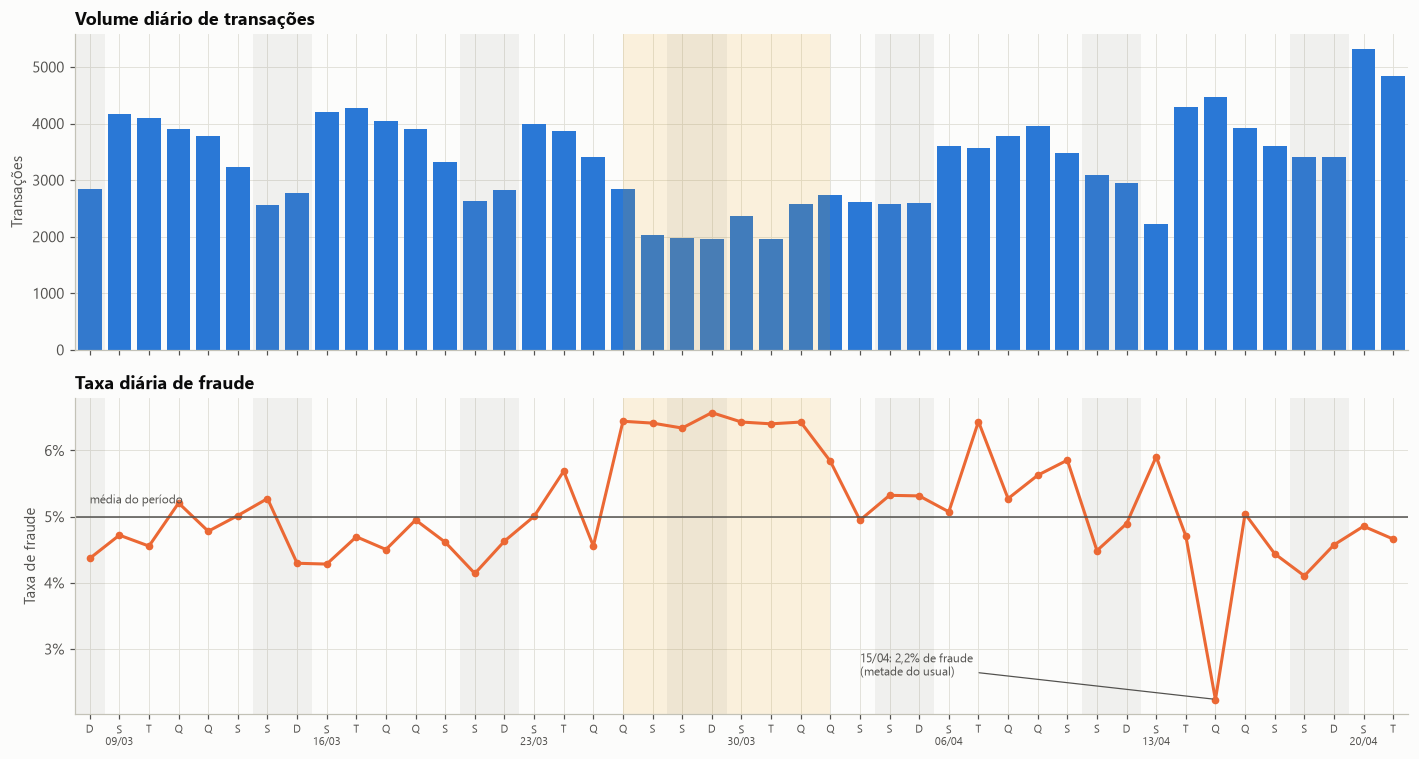

In [18]:
# Dois gráficos separados (um eixo cada): volume e taxa de fraude diária
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
axes[0].bar(diario.index, diario["transacoes"], color=gr.AZUL, width=0.8)
axes[0].set(title="Volume diário de transações", ylabel="Transações")
axes[1].plot(diario.index, diario["taxa"], color=gr.LARANJA, marker="o", ms=4)
axes[1].axhline(df["fraude"].mean(), color=gr.TINTA_2, lw=1)
axes[1].text(diario.index[0], df["fraude"].mean() + 0.002, "média do período", color=gr.TINTA_2, fontsize=8)
axes[1].set(title="Taxa diária de fraude", ylabel="Taxa de fraude")
gr.formatar_pct(axes[1], casas=0)

# Destaques: período de menor volume / maior fraude e o dia atípico de 15/04
for ax in axes:
    ax.axvspan(pd.Timestamp("2020-03-26"), pd.Timestamp("2020-04-02"), color=gr.AMARELO, alpha=0.12, lw=0)
axes[1].annotate("15/04: 2,2% de fraude\n(metade do usual)", xy=(pd.Timestamp("2020-04-15"), 0.0224),
                 xytext=(pd.Timestamp("2020-04-03"), 0.026), fontsize=8, color=gr.TINTA_2,
                 arrowprops=dict(arrowstyle="-", color=gr.TINTA_2, lw=0.8))

# Eixo x por dia da semana, para enxergar sazonalidade semanal:
# inicial do dia (S T Q Q S S D), data completa só nas segundas, e fins de semana sombreados
INICIAIS = ["S", "T", "Q", "Q", "S", "S", "D"]   # 0=segunda ... 6=domingo
rotulos = [f"{INICIAIS[d.weekday()]}\n{d:%d/%m}" if d.weekday() == 0 else INICIAIS[d.weekday()]
           for d in diario.index]
for ax in axes:
    for d in diario.index[diario.index.day_of_week >= 5]:      # sábado e domingo
        ax.axvspan(d - pd.Timedelta(hours=12), d + pd.Timedelta(hours=12), color=gr.CINZA, alpha=0.10, lw=0)
axes[1].set_xticks(diario.index)
axes[1].set_xticklabels(rotulos, fontsize=7, color=gr.TINTA_2)
axes[1].set_xlim(diario.index[0] - pd.Timedelta(hours=12), diario.index[-1] + pd.Timedelta(hours=12))
plt.tight_layout()

**Achados:**

1. O volume diário cai cerca de 35% e a taxa de fraude sobe de ~4,7% para ~6,4% entre
   os períodos de 26/03 e 02/04 (faixa amarela),voltando a ~4,9% depois. 
   **Hipótese**: início das quarentenas da COVID-19 na região?
2. O maior dia "atípico" é 15/04/2020, com volume normal, mas metade da taxa de fraude usual. 
   **Hipótese**: evento de negócio (campanha), ou um problema de rotulagem/maturação?
3. Como efeito da sazonalidade semanal, o volume cai cerca de 25% nos sábados e domingos, mas a taxa de
   fraude não acompanha e fica entre 4,7% e 5,5% em todos os dias da semana. Ou seja, o efeito
   semanal é de exposição (volume), não de risco por transação.

**Resultado:** o processo definitivamente **não é estacionário**, pois apresenta fatores históricos que influenciam em suas estatísticas, 
tais como sazonalidade, pandemia e outros eventos. 

> Isso reforça a necessidade de fazer uma **validação out-of-time** em vez de uma **validação aleatória** e exige monitoramento de estabilidade em produção.

> O rótulo também pode estar **subrotulado**, porque nem todas as fraudes que ocorreram foram necessariamente identificadas, investigadas e confirmadas até o momento de extração do dataset.
Por isso, para um cenário real, seria necessário confirmar a data de corte desse rótulo.

## 5. Estratégia de particionamento (out-of-time)

Dividimos a base pela data para simular uso real. Ou seja, treinar com o passado e decidir sobre o futuro.

| Partição | Período | Uso |
|---|---|---|
| **Treino** | 08/03 – 31/03 | ajuste dos modelos e das features |
| **Validação** | 01/04 – 10/04 | escolha de hiperparâmetros, calibração, ponto de corte |
| **Teste (OOT)** | 11/04 – 21/04 | avaliação final, usada apenas uma única vez (notebook 07) |

Para comparar algoritmos com maior robustez, aplicamos também uma **validação cruzada temporal em janela
expansiva**, com 3 dobras semanais, dentro do conjunto de desenvolvimento (treino + validação). 

Assim, em cada dobra o modelo é treinado com tudo que vem antes da janela de validação, e avaliado apenas em transações posteriores.

Posteriormente, retreinaremos um novo modelo usando todo o conjunto de desenvolvimento, que será avaliado no conjunto de teste final (out-of-time).

> Por que não usar CV com 3 dobras? **R:** Porque estaremos treinando com certo padrão e avaliando com outro. A validação utilizaria um conhecimento que no momento do treino não estava disponível.

> Por que não usar janela deslizante em vez de expansiva? **R:** Porque na janela expansiva o modelo acumula conhecimento entre as dobras. Isso é muito interessante em casos de fraude para aproveitar mais exemplos positivos e negativos conforme avançamos no tempo.

In [19]:
df = df.sort_values("fecha").reset_index(drop=True)
df["particao"] = dados.atribuir_particao(df)

resumo_part = (df.groupby("particao", sort=False)
                 .agg(inicio=("fecha", "min"), fim=("fecha", "max"), transacoes=("fraude", "size"),
                      fraudes=("fraude", "sum"), taxa_fraude=("fraude", "mean"),
                      valor_total=("monto", "sum")))
resumo_part["%_base"] = resumo_part["transacoes"] / len(df)
resumo_part

,inicio,fim,transacoes,fraudes,taxa_fraude,valor_total,%_base
particao,,,,,,,
treino,2020-03-08 00:02:15,2020-03-31 23:56:36,76961,3877,0.0504,"3,522,441.7000",0.5131
validacao,2020-04-01 00:00:45,2020-04-10 23:59:43,31505,1769,0.0561,"1,283,646.3400",0.2100
teste,2020-04-11 00:00:44,2020-04-21 23:59:56,41534,1854,0.0446,"1,722,382.0800",0.2769


In [20]:
# Folds temporais (janela expansiva) dentro de treino+validação
dev = df[df["particao"] != "teste"].reset_index(drop=True)
linhas = []
for k, (idx_tr, idx_va) in enumerate(dados.folds_temporais(dev["fecha"]), start=1):
    linhas.append({
        "fold": k,
        "treino_ate": dev.loc[idx_tr, "fecha"].max().date(),
        "valida_de": dev.loc[idx_va, "fecha"].min().date(),
        "valida_ate": dev.loc[idx_va, "fecha"].max().date(),
        "n_treino": len(idx_tr), "n_valid": len(idx_va),
        "taxa_fraude_valid": dev.loc[idx_va, "fraude"].mean(),
    })
pd.DataFrame(linhas).set_index("fold")

,treino_ate,valida_de,valida_ate,n_treino,n_valid,taxa_fraude_valid
fold,,,,,,
1,2020-03-21,2020-03-22,2020-03-28,49731,20935,0.0546
2,2020-03-28,2020-03-29,2020-04-04,70666,16800,0.0595
3,2020-04-04,2020-04-05,2020-04-10,87466,21000,0.0560


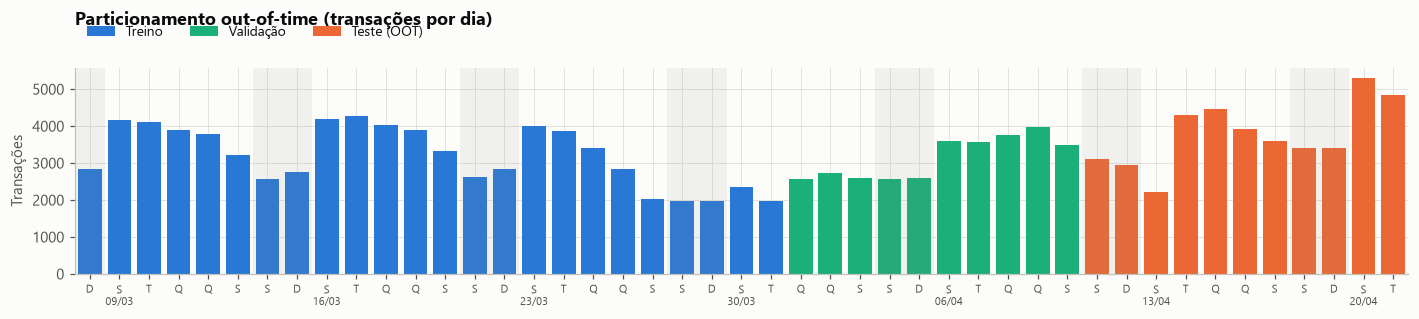

In [21]:
# Linha do tempo das partições
fig, ax = plt.subplots(figsize=(13, 3))
cores = {"treino": gr.AZUL, "validacao": gr.VERDE_AGUA, "teste": gr.LARANJA}
nomes = {"treino": "Treino", "validacao": "Validação", "teste": "Teste (OOT)"}
for part, g in df.groupby("particao", sort=False):
    d = g.set_index("fecha").resample("D").size()
    ax.bar(d.index, d.values, color=cores[part], width=0.8, label=nomes[part])
ax.set_ylabel("Transações")
ax.set_title("Particionamento out-of-time (transações por dia)", pad=28)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.08), ncol=3)

# Eixo x por dia da semana, para enxergar sazonalidade semanal:
# inicial do dia (S T Q Q S S D), data completa só nas segundas, e fins de semana sombreados
INICIAIS = ["S", "T", "Q", "Q", "S", "S", "D"]   # 0=segunda ... 6=domingo
rotulos = [f"{INICIAIS[d.weekday()]}\n{d:%d/%m}" if d.weekday() == 0 else INICIAIS[d.weekday()]
           for d in diario.index]
for d in diario.index[diario.index.day_of_week >= 5]:          # sábado e domingo
    ax.axvspan(d - pd.Timedelta(hours=12), d + pd.Timedelta(hours=12), color=gr.CINZA, alpha=0.10, lw=0)
ax.set_xticks(diario.index)
ax.set_xticklabels(rotulos, fontsize=7, color=gr.TINTA_2)
ax.set_xlim(diario.index[0] - pd.Timedelta(hours=12), diario.index[-1] + pd.Timedelta(hours=12))
plt.tight_layout()

## 6. Persistência da base particionada

In [22]:
cfg.DIR_PROCESSADO.mkdir(parents=True, exist_ok=True)
df.to_parquet(cfg.ARQUIVO_BASE, index=False)
print("Base salva em", cfg.ARQUIVO_BASE.relative_to(cfg.RAIZ), "->", df.shape)

Base salva em data\processed\base.parquet -> (150000, 21)


## 7. Conclusões

1. **150k** transações com **5%** de fraude em apenas **45** dias de avaliação. 
    * Trata-se de um problema desbalanceado, com custo assimétrico e decisão binária; 
    * As métricas utilizadas serão PR AUC, ROC AUC/KS, Recall @ FPR e **lucro em R$**.
2. Os dados foram limpos, mas algumas particularidades se destacam:
    * variáveis nulas em blocos (`b/c`, `d/m`) que devemos tomar cuidado na hora de incorporar (modelos lineares);
    * `f` com valores negativos;
    * `k` com um valor distinto por linha, candidata a ruído (será testada futuramente).
3. O processo não é estacionário, pois há mudança de regime no fim de março e um dia anômalo em 15/04. Isso justifica a decisão de **validação out-of-time** e o monitoramento contínuo em produção.

4. Particionamento definido: 
    * **treino de 08/03 à 31/03**;
    * **validação de 01/04 à 10/04**;
    * **teste OOT de 11/04 à 21/04** (intocado até futuras avaliações).